In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
from sklearn.model_selection import train_test_split

from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import accuracy_score
from sklearn.model_selection import cross_val_score

from sklearn.preprocessing import KBinsDiscretizer
from sklearn.compose import ColumnTransformer

In [9]:
df = pd.read_csv("train.csv",usecols=['Age','Fare','Survived'])

In [10]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [11]:
df.describe()

,Survived,Age,Fare
count,891.000000,714.000000,891.000000
mean,0.383838,29.699118,32.204208
std,0.486592,14.526497,49.693429
min,0.000000,0.420000,0.000000
25%,0.000000,20.125000,7.910400
50%,0.000000,28.000000,14.454200
75%,1.000000,38.000000,31.000000
max,1.000000,80.000000,512.329200


In [15]:
df.shape

(891, 3)

In [16]:
df.dropna(inplace=True)

In [17]:
df.shape

(714, 3)

In [18]:
X = df.iloc[:,1:]
Y = df.iloc[:,0]

In [19]:
x_train,x_test,y_train,y_test = train_test_split(X,Y,test_size=0.2,random_state=42)

In [20]:
x_train.head()

,Age,Fare
328,31.0,20.5250
73,26.0,14.4542
253,30.0,16.1000
719,33.0,7.7750
666,25.0,13.0000


In [21]:
clf = DecisionTreeClassifier()

In [22]:
clf.fit(x_train,y_train)
y_pred = clf.predict(x_test,)

In [24]:
accuracy_score(y_test,y_pred)

0.6293706293706294

In [25]:
np.mean(cross_val_score(DecisionTreeClassifier(),X,Y,cv=10,scoring='accuracy'))

np.float64(0.6331572769953052)

In [53]:
kbin_age = KBinsDiscretizer(n_bins=15,encode='ordinal',strategy='quantile')
kbin_fare = KBinsDiscretizer(n_bins=15,encode='ordinal',strategy='quantile')

In [54]:
trf = ColumnTransformer([
    ('first',kbin_age,[0]),
    ('second',kbin_fare,[1])
])

In [55]:
x_train_trf = trf.fit_transform(x_train)
x_test_trf = trf.transform(x_test)

In [56]:
trf.named_transformers_

{'first': KBinsDiscretizer(encode='ordinal', n_bins=15),
 'second': KBinsDiscretizer(encode='ordinal', n_bins=15)}

In [57]:
trf.named_transformers_["first"].n_bins_

array([15])

In [58]:
trf.named_transformers_["second"].bin_edges_

array([array([  0.    ,   7.25  ,   7.775 ,   7.8958,   8.1583,  10.5   ,
               13.    ,  14.4542,  18.75  ,  26.    ,  26.55  ,  31.275 ,
               51.4792,  76.2917, 108.9   , 512.3292])                   ],
      dtype=object)

In [59]:
output=pd.DataFrame({
    "age":x_train["Age"],
    "age_trf":x_train_trf[:,0],
    "fare":x_train["Fare"],
    "fare_trf":x_train_trf[:,1]
})

In [60]:
output["age_labels"]=pd.cut(x=x_train["Age"],bins=trf.named_transformers_["first"].bin_edges_[0].tolist())
output["fare_labels"]=pd.cut(x=x_train["Fare"],bins=trf.named_transformers_["second"].bin_edges_[0].tolist())

In [61]:
output.sample(5)

,age,age_trf,fare,fare_trf,age_labels,fare_labels
506,33.0,9.0,26.0000,9.0,"(32.0, 35.0]","(18.75, 26.0]"
97,23.0,5.0,63.3583,12.0,"(21.0, 23.0]","(51.479, 76.292]"
700,18.0,2.0,227.5250,14.0,"(16.0, 19.0]","(108.9, 512.329]"
472,33.0,9.0,27.7500,10.0,"(32.0, 35.0]","(26.55, 31.275]"
544,50.0,13.0,106.4250,13.0,"(47.0, 54.0]","(76.292, 108.9]"


In [62]:
clf = DecisionTreeClassifier()
clf.fit(x_train_trf,y_train)
y_pred2 = clf.predict(x_test_trf)

In [63]:
accuracy_score(y_test,y_pred2)

0.6363636363636364

In [64]:
X_trf=trf.fit_transform(X)
np.mean(cross_val_score(DecisionTreeClassifier(),X_trf,Y,cv=10,scoring="accuracy"))

np.float64(0.6737676056338028)

Text(0.5, 1.0, 'Age after Binning')

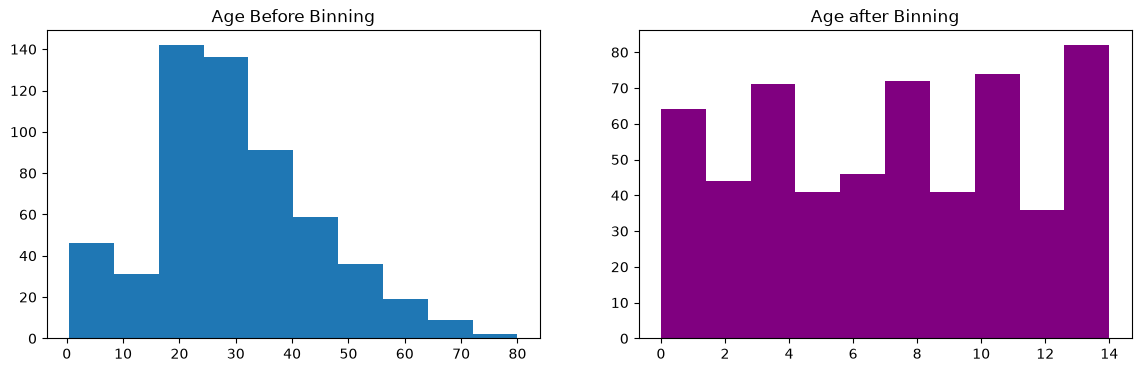

In [77]:
plt.figure(figsize=(14,4))

plt.subplot(121)
plt.hist(x_train["Age"])
plt.title("Age Before Binning",)

plt.subplot(122)
plt.hist(x_train_trf[:,0],color="purple")
plt.title("Age after Binning")

Text(0.5, 1.0, 'Fare after Binning')

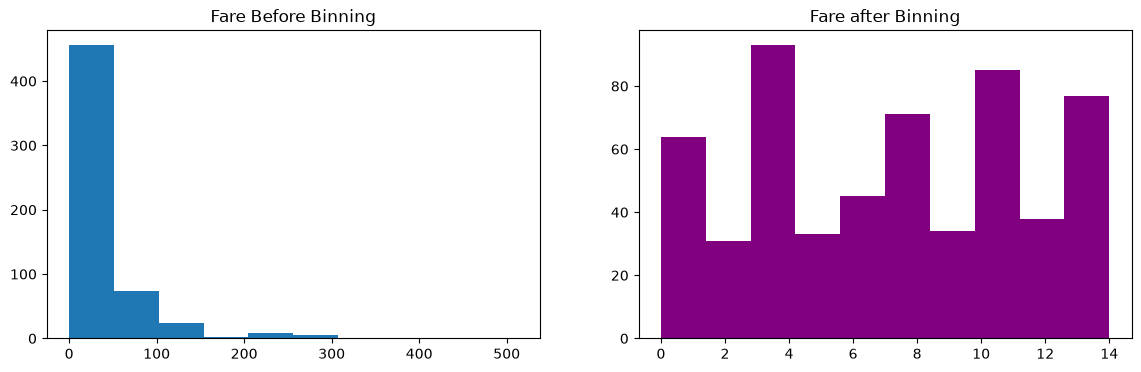

In [78]:
plt.figure(figsize=(14,4))

plt.subplot(121)
plt.hist(x_train["Fare"])
plt.title("Fare Before Binning")

plt.subplot(122)
plt.hist(x_train_trf[:,1],color="purple")
plt.title("Fare after Binning")

In [79]:
def discretize(bins,strategy):
    kbin_age = KBinsDiscretizer(n_bins=bins,encode='ordinal',strategy=strategy)
    kbin_fare = KBinsDiscretizer(n_bins=bins,encode='ordinal',strategy=strategy)
    
    trf = ColumnTransformer([
        ('first',kbin_age,[0]),
        ('second',kbin_fare,[1])
    ])
    
    X_trf = trf.fit_transform(X)
    print(np.mean(cross_val_score(DecisionTreeClassifier(),X,Y,cv=10,scoring='accuracy')))
    
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    plt.hist(X['Age'])
    plt.title("Before")

    plt.subplot(122)
    plt.hist(X_trf[:,0],color='red')
    plt.title("After")

    plt.show()
    
    plt.figure(figsize=(14,4))
    plt.subplot(121)
    plt.hist(X['Fare'])
    plt.title("Before")

    plt.subplot(122)
    plt.hist(X_trf[:,1],color='red')
    plt.title("Fare")

    plt.show()

0.6373239436619718


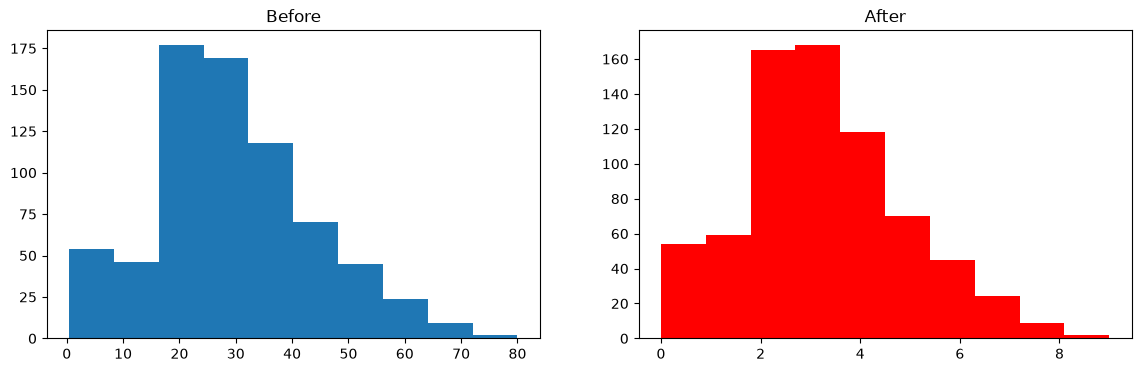

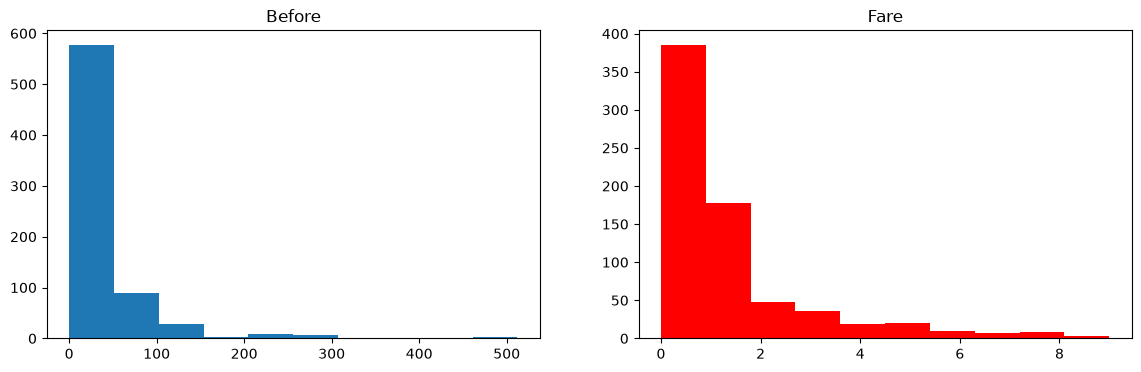

In [86]:
discretize(10,"kmeans")